In [1]:
import numpy as np
import pandas as pd
import scipy.optimize
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
import math
import pyperclip 
from scipy.stats import norm


FWHM = 172.32 ± 9.13
1/e width = 206.98 ± 10.97
Divergence half-angle width_1e = 0.664 ± 0.128 deg
Divergence half-angle FWHM= 0.260 ± 0.106 deg
443.48832426433813


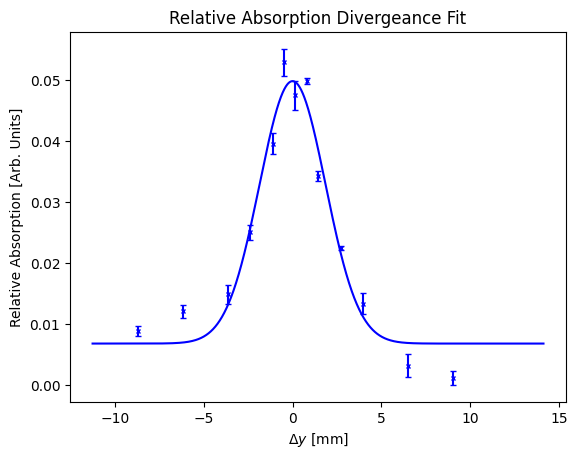

In [12]:
filepath3 = "112825/divergence_results.csv"

df = pd.read_csv(filepath3)

x_full  = np.concatenate([df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy()])
y_full  = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),df['Scale3'].to_numpy(),df['Scale4'].to_numpy()])

# x_full = df['height']

# # Compute mean and standard error across Scale1–Scale4
# scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

# y_full = np.mean(scales, axis=1)
# y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


def gaussian(x, A, x0, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100, 0.0], 
    absolute_sigma= False
)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


x_fit = np.linspace(0,1000,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar((x_full - popt[1]) / (39.3701 * 1), y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "blue")
plt.plot((x_fit - popt[1]) / (39.3701 * 1), y_fit,c="blue")
plt.title("Relative Absorption Divergeance Fit")
plt.xlabel(r'$\Delta y$ [mm]')

plt.ylabel("Relative Absorption [Arb. Units]")



# Extract sigma and its error
sigma = popt[2]
sigma_err = np.sqrt(pvoc[2, 2])

# Calculate widths
FWHM = 2 * np.sqrt(2 * np.log(2)) * sigma
width_1e = 2 * np.sqrt(2) * sigma

# Propagate errors
FWHM_err = 2 * np.sqrt(2 * np.log(2)) * sigma_err
width_1e_err = 2 * np.sqrt(2) * sigma_err

print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")



nozzleheight = 0.150
beamgrowth = width_1e/1000 - nozzleheight
distancenozzle = 2.46

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * width_1e_err   # propagate

print(f"Divergence half-angle width_1e = {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")

nozzleheight = 0.150
beamgrowth = FWHM/1000 - nozzleheight
distancenozzle = 2.46

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * FWHM_err   # propagate

print(f"Divergence half-angle FWHM= {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")


offset = popt[3]
dx = popt[1]
print(dx)



FWHM = 172.32 ± 9.13
1/e width = 206.98 ± 10.97
Divergence half-angle width_1e = 0.664 ± 0.128 deg
Divergence half-angle FWHM= 0.260 ± 0.106 deg
443.48832426433813


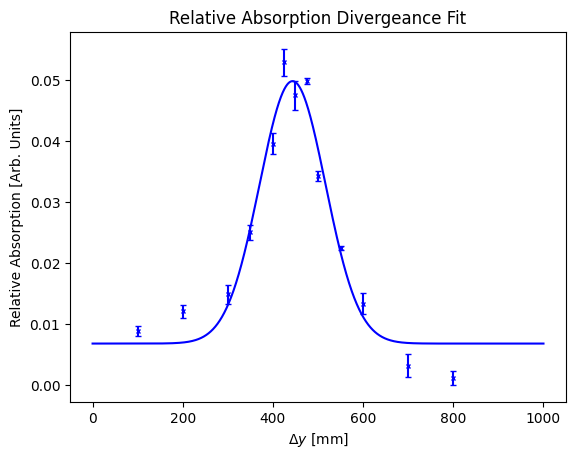

In [ ]:
filepath3 = "112825/divergence_results_deg1.csv"

df = pd.read_csv(filepath3)

x_full  = np.concatenate([df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy()])
y_full  = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),df['Scale3'].to_numpy(),df['Scale4'].to_numpy()])

# x_full = df['height']

# # Compute mean and standard error across Scale1–Scale4
# scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

# y_full = np.mean(scales, axis=1)
# y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


def gaussian(x, A, x0, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100, 0.0], 
    absolute_sigma= False
)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


x_fit = np.linspace(0,1000,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar(x_full, y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "blue")
plt.plot(x_fit , y_fit,c="blue")
plt.title("Relative Absorption Divergeance Fit")
plt.xlabel(r'$\Delta y$ [mm]')

plt.ylabel("Relative Absorption [Arb. Units]")



# Extract sigma and its error
sigma = popt[2]
sigma_err = np.sqrt(pvoc[2, 2])

# Calculate widths
FWHM = 2 * np.sqrt(2 * np.log(2)) * sigma
width_1e = 2 * np.sqrt(2) * sigma

# Propagate errors
FWHM_err = 2 * np.sqrt(2 * np.log(2)) * sigma_err
width_1e_err = 2 * np.sqrt(2) * sigma_err

print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")



nozzleheight = 0.150
beamgrowth = width_1e/1000 - nozzleheight
distancenozzle = 2.46

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * width_1e_err   # propagate

print(f"Divergence half-angle width_1e = {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")

nozzleheight = 0.150
beamgrowth = FWHM/1000 - nozzleheight
distancenozzle = 2.46

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * FWHM_err   # propagate

print(f"Divergence half-angle FWHM= {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")


offset = popt[3]
dx = popt[1]
print(dx)



Text(-1.4353957885720856, 0.38, '1/e width')

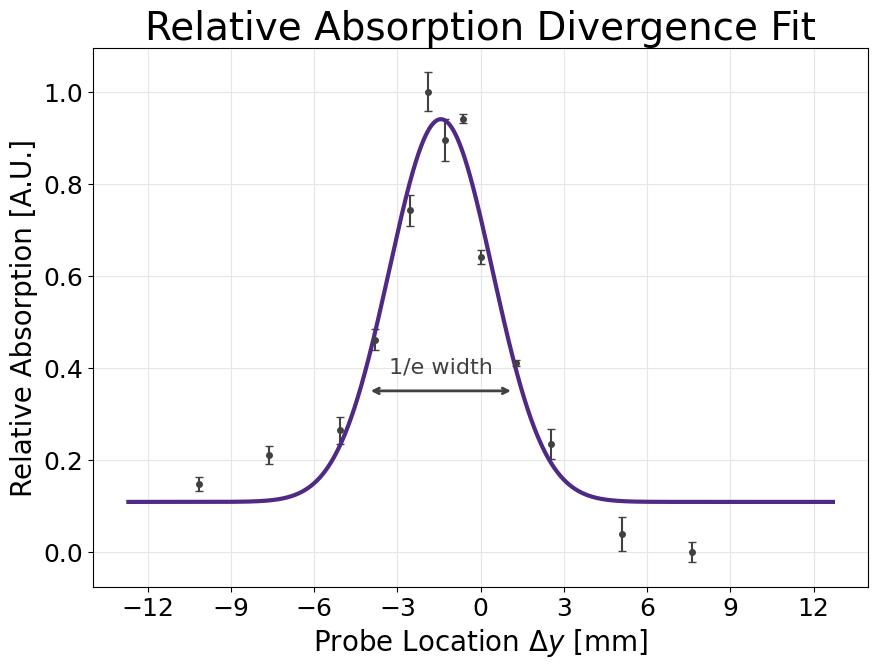

In [8]:
plt.figure(figsize=(10, 7))

plt.errorbar((x_full - 500) / (39.3701 * 1),
              (y_full - np.min(y_full))/(np.max(y_full) - np.min(y_full)), 
             yerr=y_err/(y_full.max()-y_full.min()),
             fmt='o',markersize=4,linestyle='None',capsize=3,c= "#414141")
plt.plot((x_fit - 500) / (39.3701 * 1), 
         (y_fit - np.min(y_full))/(np.max(y_full) - np.min(y_full)),
         c="#4E2A84", lw = "3")

plt.grid(True, color='0.9', linewidth=0.8)
plt.title("Relative Absorption Divergence Fit",fontsize = "28")
plt.xticks(np.arange(-12, 12.1, 3),fontsize = "18")
plt.yticks(fontsize = "18")
plt.xlabel(r'Probe Location $\Delta y$ [mm]',fontsize = "20")
plt.ylabel("Relative Absorption [A.U.]",fontsize = "20")

# # --- FWHM double-arrow on the normalized plot ---
# sigma  = popt[2]
# FWHM   = 2*np.sqrt(2*np.log(2))*sigma

# x0_plot   = (popt[1] - 500)/39.3701
# half_span = (FWHM/2)/39.3701
# xL, xR    = x0_plot - half_span, x0_plot + half_span

# ax = plt.gca()
# ax.annotate('', xy=(xL, 0.5), xytext=(xR, 0.5),
#             arrowprops=dict(arrowstyle='<->', lw=2, color='#4E2A84'))
# ax.text(x0_plot, 0.4, 'FWHM', ha='center', va='bottom', fontsize=16, color='#4E2A84')

# --- 1/e width double-arrow on the normalized plot ---


x0_plot   = (popt[1] - 500)/39.3701
half_span = (width_1e/2)/39.3701
xL, xR    = x0_plot - half_span, x0_plot + half_span

ax = plt.gca()
ax.annotate('', xy=(xL, 0.35), xytext=(xR, 0.35),
            arrowprops=dict(arrowstyle='<->', lw=2, color='#414141'))
ax.text(x0_plot, 0.38, '1/e width', ha='center', va='bottom',
        fontsize=16, color='#414141')

0.5343358592967682
sigma = 0.685352 ± 0.065
P(|X| ≤ 0.5) = 0.534336 ± 0.042


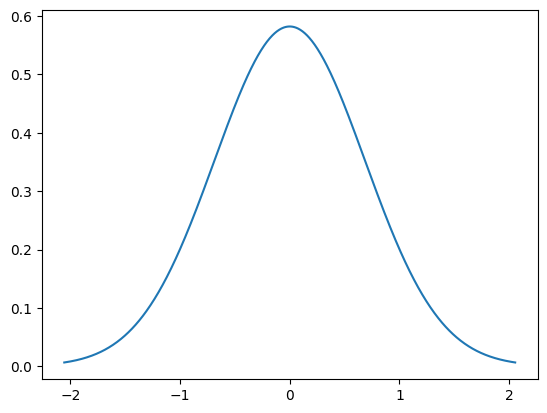

In [3]:
#Capture efficiency  
Distance_z1_gr = (19.685-2.46)*12*100#ft

div_1e = 0.76 #degree
div_1e_err =0.100 #degree

z1_1e =  214.79 #thous an inch
z1_1e_err = 7.37 #thous an inch

gr_1e = (z1_1e + 2*Distance_z1_gr*math.tan(div_1e*math.pi/180))*2.54/1000 #cm


# get normal (gaussian) dist
sigma = gr_1e / (2*np.sqrt(2))
mu = 0
x = np.linspace(-3*sigma, 3*sigma, 1000)
f = norm.pdf(x, mu, sigma)

plt.plot(x,f)

P = norm.cdf(0.5, mu, sigma) - norm.cdf(-0.5, mu, sigma)
print(P)

# inputs (your values)
Distance_z1_gr = (19.685-2.46)*12*100      # same units you used for D
div_deg = 0.76
div_deg_err = 0.100
z_thou = 214.79
z_thou_err = 7.37

# constants
c = 2.54/1000.0                             # cm per thou
theta = math.radians(div_deg)
D = Distance_z1_gr

# g_{1/e}, sigma
g_1e = (z_thou + 2*D*math.tan(theta)) * c   # cm
sigma = g_1e / (2*math.sqrt(2))

# derivatives
dg_dz = c
dg_ddivdeg = 2*D*(1/math.cos(theta))**2 * c * math.pi/180.0
dsigma_dz = dg_dz / (2*math.sqrt(2))
dsigma_ddivdeg = dg_ddivdeg / (2*math.sqrt(2))

# sigma uncertainty
var_sigma = (dsigma_dz * z_thou_err)**2 + (dsigma_ddivdeg * div_deg_err)**2
sigma_err = math.sqrt(var_sigma)

# probability within [-0.5, 0.5]
a = 0.5
P = norm.cdf(a, 0, sigma) - norm.cdf(-a, 0, sigma)

# dP/dsigma
t = a / sigma
phi = math.exp(-0.5*t*t) / math.sqrt(2*math.pi)
dP_dsigma = -2*a*phi / (sigma**2)

# P uncertainty
P_err = abs(dP_dsigma) * sigma_err

print(f"sigma = {sigma:.6g} ± {sigma_err:.2g}")
print(f"P(|X| ≤ 0.5) = {P:.6f} ± {P_err:.2g}")



In [56]:
fig, ax = plt.subplots(figsize=(10, 7))

ax.errorbar((x_full - 500)/(39.3701*1),
            (y_full - np.min(y_full))/(np.max(y_full) - np.min(y_full)),
            yerr=y_err/(y_full.max()-y_full.min()),
            fmt='o', markersize=8, linestyle='None', capsize=5, c="#414141")

ax.plot((x_fit - 500)/(39.3701*1),
        (y_fit - np.min(y_full))/(np.max(y_full) - np.min(y_full)),
        c="#4E2A84", lw=8)

ax.set_axis_off()  # hide axes, ticks, frame
plt.gca().invert_xaxis()

fig.savefig('overlay_plot.png', dpi=300, transparent=True, bbox_inches='tight', pad_inches=0)
plt.close(fig)


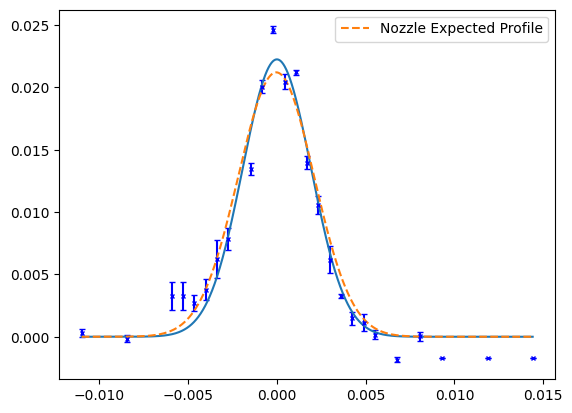

In [ ]:


# --- Add this AFTER your existing code ---

# ===== Mathematica constants (fixed) =====
theta_deg = 2.638     # Divergence capillaries, degrees
theta = np.deg2rad(theta_deg)
Delta_x = 0.062484               # m (distance nozzle/capillaries to probe point)
BeamWidth = 2 * Delta_x * np.tan(theta)  # 1/e width
sigma_MMA = BeamWidth / (2 * np.sqrt(2)) # Gaussian sigma
DistanceCapillaries = 0.000127   # m (SolidWorks model)
NumCaps = 21

# ===== Define G and F exactly as in Mathematica =====
def G_mma(x, delta):
    return (1.0 / (sigma_MMA * np.sqrt(2*np.pi))) * np.exp(-(x - delta)**2 / (2*sigma_MMA**2))

def F_mma(x):
    i = np.arange(1, NumCaps+1, dtype=float)
    centers = i * DistanceCapillaries
    xx = np.atleast_1d(x)[:, None]
    vals = i[None, :] * G_mma(xx, centers[None, :])
    return np.sum(vals, axis=1)

# ===== Fit model: y = A * F(x - delta) + C =====
def model_A_F_shift_C(x_meters, A, delta):
    return A * F_mma(x_meters - delta)+offset

# Use your same x-axis units (meters)
x_meters = x_full / (39.3701 * 1000.0)

# Initial guesses
A0 = (np.max(y_full) - np.min(y_full)) / max(F_mma(np.array([0.0]))[0], 1e-12)
delta0 = x_meters[np.argmax(y_full)]


popt_mma, pcov_mma = curve_fit(
    model_A_F_shift_C, x_meters, y_full,
    p0=[A0, delta0],
    # If you want to use uncertainties:
    # sigma=y_err, absolute_sigma=True,
    maxfev=20000
)
A_fit, delta_fit = popt_mma
perr_mma = np.sqrt(np.diag(pcov_mma))
A_err, delta_err = perr_mma

# Plot the MMA-model fit on top of your existing figure
x_fit_m = np.linspace(x_meters.min(), x_meters.max(), 1000)
y_fit_m = model_A_F_shift_C(x_fit_m, A_fit, delta_fit)-offset

plt.errorbar((x_full-dx) / (39.3701 * 1000), y_full - offset, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "blue")
plt.plot((x_fit-dx) / (39.3701 * 1000), y_fit - offset)

plt.plot(x_fit_m-dx/ (39.3701 * 1000.0), y_fit_m, label='Nozzle Expected Profile', linestyle = '--')
plt.legend()
plt.show()


FWHM = 316.20 ± 28.00
1/e width = 379.80 ± 33.63
Divergence half-angle nozzle width_1e= 0.535 ± 0.078 deg
Divergence half-angle nozzle FWHM= 0.387 ± 0.065 deg
Divergence half-angle Near 1/e = 0.481 ± 0.100 deg
Divergence half-angle Near FWHM = 0.400 ± 0.083 deg
507.14067008738647


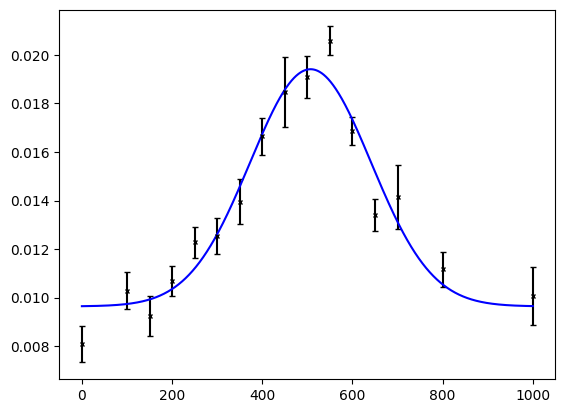

In [76]:
filepath3 = "101225/Far/RelativeAbsFar.csv"

df = pd.read_csv(filepath3)

x_full  = np.concatenate([df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy()])
y_full  = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),df['Scale3'].to_numpy(),df['Scale4'].to_numpy()])

# x_full = df['height']

# # Compute mean and standard error across Scale1–Scale4
# scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

# y_full = np.mean(scales, axis=1)
# y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


def gaussian(x, A, x0, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100, 0.0], 
    absolute_sigma= False
)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


x_fit = np.linspace(0,1000,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar(x_full, y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "black")
plt.plot(x_fit, y_fit,c="blue")

# Extract sigma and its error
sigma = popt[2]
sigma_err = np.sqrt(pvoc[2, 2])

# Calculate widths
FWHM = 2 * np.sqrt(2 * np.log(2)) * sigma
width_1e = 2 * np.sqrt(2) * sigma

# Propagate errors
FWHM_err = 2 * np.sqrt(2 * np.log(2)) * sigma_err
width_1e_err = 2 * np.sqrt(2) * sigma_err

print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")



nozzleheight = 0.150
beamgrowth = width_1e/1000 - nozzleheight
distancenozzle = 12.3

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * width_1e_err   # propagate

print(f"Divergence half-angle nozzle width_1e= {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")



nozzleheight = 0.150
beamgrowth = FWHM/1000 - nozzleheight
distancenozzle = 12.3

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * FWHM_err   # propagate

print(f"Divergence half-angle nozzle FWHM= {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")

# --- inputs (thou = thousandths of an inch; distance in inches) ---
# FAR plane
width_1e_thou, width_1e_err_thou = width_1e, width_1e_err
FWHM_thou,     FWHM_err_thou     = FWHM, FWHM_err

# NEAR plane
Near_width_1e_thou, Near_width_1e_err_thou = 214.59, 7.36
Near_FWHM_thou,     Near_FWHM_err_thou     = 178.83, 6.13

distanceNear_in = 9.84

def div_half_angle_from_diff(w_far_thou, sig_far_thou, w_near_thou, sig_near_thou, d_in):
    # beam growth g in inches from width difference
    g_in = (w_far_thou - w_near_thou) / 1000.0
    u = (g_in / 2.0) / d_in
    theta_rad = math.atan(u)
    # propagate both widths
    dtheta_dg = (1.0 / (1.0 + u*u)) * (1.0 / (2.0 * d_in))   # rad per inch
    sigma_g_in = math.hypot(sig_far_thou, sig_near_thou) / 1000.0
    sigma_theta_rad = abs(dtheta_dg) * sigma_g_in
    return theta_rad, sigma_theta_rad

# 1/e case
theta_1e, s_1e = div_half_angle_from_diff(
    width_1e_thou, width_1e_err_thou,
    Near_width_1e_thou, Near_width_1e_err_thou,
    distanceNear_in
)
print(f"Divergence half-angle Near 1/e = {theta_1e*180/math.pi:.3f} ± {s_1e*180/math.pi:.3f} deg")

# FWHM case
theta_f, s_f = div_half_angle_from_diff(
    FWHM_thou, FWHM_err_thou,
    Near_FWHM_thou, Near_FWHM_err_thou,
    distanceNear_in
)
print(f"Divergence half-angle Near FWHM = {theta_f*180/math.pi:.3f} ± {s_f*180/math.pi:.3f} deg")


offset = popt[3]
dx = popt[1]
print(dx)

FWHM = 893.74 ± 51.07
1/e width = 1073.49 ± 61.34
Divergence half-angle = 2.150 ± 0.119 deg


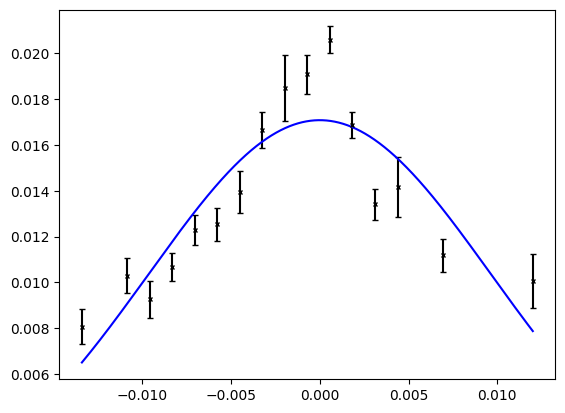

In [ ]:
filepath3 = "101225/Far/RelativeAbsFar.csv"

df = pd.read_csv(filepath3)

x_full  = np.concatenate([df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy()])
y_full  = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),df['Scale3'].to_numpy(),df['Scale4'].to_numpy()])

# x_full = df['height']

# # Compute mean and standard error across Scale1–Scale4
# scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

# y_full = np.mean(scales, axis=1)
# y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


def gaussian(x, A, x0, sigma):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2))


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100], 
    absolute_sigma= False
)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


x_fit = np.linspace(0,1000,2000)
y_fit = gaussian(x_fit, *popt) 

plt.errorbar((x_full - popt[1]) / (39.3701 * 1000), y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "black")
plt.plot((x_fit - popt[1]) / (39.3701 * 1000), y_fit,c="blue")

# Extract sigma and its error
sigma = popt[2]
sigma_err = np.sqrt(pvoc[2, 2])

# Calculate widths
FWHM = 2 * np.sqrt(2 * np.log(2)) * sigma
width_1e = 2 * np.sqrt(2) * sigma

# Propagate errors
FWHM_err = 2 * np.sqrt(2 * np.log(2)) * sigma_err
width_1e_err = 2 * np.sqrt(2) * sigma_err

print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")



nozzleheight = 0.150
beamgrowth = width_1e/1000 - nozzleheight
distancenozzle = 12.3

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * FWHM_err   # propagate

print(f"Divergence half-angle = {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")


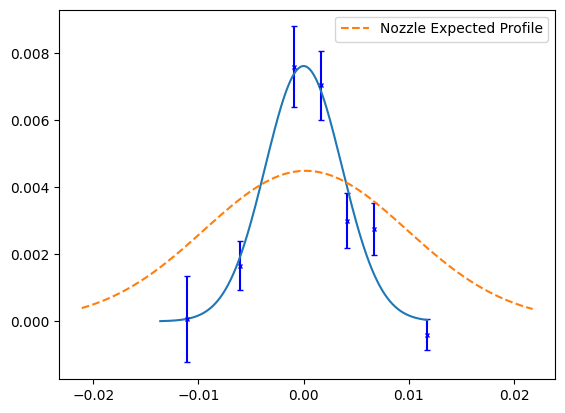

In [11]:


# --- Add this AFTER your existing code ---

# ===== Mathematica constants (fixed) =====
theta_deg = 2.5   # Divergence capillaries, degrees
theta = np.deg2rad(theta_deg)
Delta_x = 0.312              # m (distance nozzle/capillaries to probe point)
BeamWidth = 2 * Delta_x * np.tan(theta)  # 1/e width
sigma_MMA = BeamWidth / (2 * np.sqrt(2)) # Gaussian sigma
DistanceCapillaries = 0.000127   # m (SolidWorks model)
NumCaps = 21

# ===== Define G and F exactly as in Mathematica =====
def G_mma(x, delta):
    return (1.0 / (sigma_MMA * np.sqrt(2*np.pi))) * np.exp(-(x - delta)**2 / (2*sigma_MMA**2))

def F_mma(x):
    i = np.arange(1, NumCaps+1, dtype=float)
    centers = i * DistanceCapillaries
    xx = np.atleast_1d(x)[:, None]
    vals = i[None, :] * G_mma(xx, centers[None, :])
    return np.sum(vals, axis=1)

# ===== Fit model: y = A * F(x - delta) + C =====
def model_A_F_shift_C(x_meters, A, delta):
    return A * F_mma(x_meters - delta)+offset

# Use your same x-axis units (meters)
x_meters = x_full / (39.3701 * 1000.0)

# Initial guesses
A0 = (np.max(y_full) - np.min(y_full)) / max(F_mma(np.array([0.0]))[0], 1e-12)
delta0 = x_meters[np.argmax(y_full)]


popt_mma, pcov_mma = curve_fit(
    model_A_F_shift_C, x_meters, y_full,
    p0=[A0, delta0],
    # If you want to use uncertainties:
    # sigma=y_err, absolute_sigma=True,
    maxfev=20000
)
A_fit, delta_fit = popt_mma
perr_mma = np.sqrt(np.diag(pcov_mma))
A_err, delta_err = perr_mma

# Plot the MMA-model fit on top of your existing figure
x_fit_m = np.linspace(x_meters.min()-0.01, x_meters.max()+0.01, 4000)
y_fit_m = model_A_F_shift_C(x_fit_m, A_fit, delta_fit)-offset

plt.errorbar((x_full-dx) / (39.3701 * 1000), y_full - offset, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "blue")
plt.plot((x_fit-dx) / (39.3701 * 1000), y_fit - offset)

plt.plot(x_fit_m-dx/ (39.3701 * 1000.0), y_fit_m, label='Nozzle Expected Profile', linestyle = '--')
plt.legend()
plt.show()


4.23380390503756
3.2902205829154685


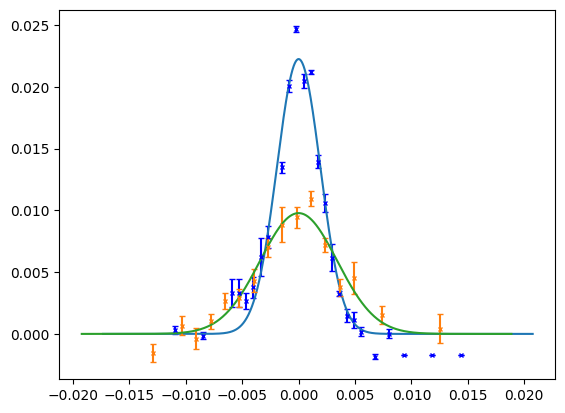

In [39]:
filepath3 = "101225/Near/RelativeAbsNear.csv"

df = pd.read_csv(filepath3)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


def gaussian(x, A, x0, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100, 0.0], 
    absolute_sigma= False,
)

x_fit = np.linspace(-250,1250,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar((x_full - popt[1]) / (39.3701 * 1000), y_full - popt[3], yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "blue")
plt.plot((x_fit-popt[1])/(39.3701*1000),y_fit-popt[3])


x_min, x_max = -250, 1250
mask = (x_fit >= x_min) & (x_fit <= x_max)

area1 = np.trapezoid(y_fit[mask]-popt[3], x_fit[mask])

print(area1)


filepath3 = "101225/Far/RelativeAbsFar.csv"

df = pd.read_csv(filepath3)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])



def gaussian(x, A, x0, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100, 0.0], 
    absolute_sigma= False,
)

x_fit = np.linspace(-250,1250,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar((x_full - popt[1]) / (39.3701 * 1000), y_full - popt[3], yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2)
plt.plot((x_fit-popt[1])/(39.3701*1000),y_fit-popt[3])


x_min, x_max = -250, 1250
mask = (x_fit >= x_min) & (x_fit <= x_max)

area2 = np.trapezoid(y_fit[mask]-popt[3], x_fit[mask])

print(area2)



4.23380390503756
12.915084162580229


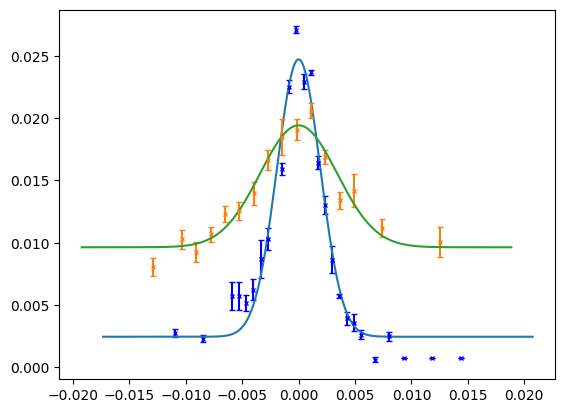

In [47]:
filepath3 = "101225/Near/RelativeAbsNear.csv"

df = pd.read_csv(filepath3)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


def gaussian(x, A, x0, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100, 0.0], 
    absolute_sigma= False,
)

x_fit = np.linspace(-250,1250,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar((x_full - popt[1]) / (39.3701 * 1000), y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "blue")
plt.plot((x_fit-popt[1])/(39.3701*1000),y_fit)


x_min, x_max = -250, 1250
mask = (x_fit >= x_min) & (x_fit <= x_max)

area1 = np.trapezoid(y_fit[mask]-popt[3], x_fit[mask])

print(area1)


filepath3 = "101225/Far/RelativeAbsFar.csv"

df = pd.read_csv(filepath3)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])



def gaussian(x, A, x0, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100, 0.0], 
    absolute_sigma= False,
)

x_fit = np.linspace(-250,1250,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar((x_full - popt[1]) / (39.3701 * 1000), y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2)
plt.plot((x_fit-popt[1])/(39.3701*1000),y_fit)


x_min, x_max = 0, 1000
mask = (x_fit >= x_min) & (x_fit <= x_max)

area2 = np.trapezoid(y_fit[mask], x_fit[mask])

print(area2)

5.461555458189345
15.45949722876553


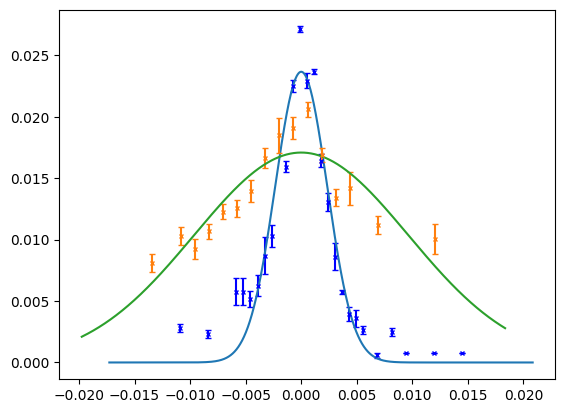

In [52]:
filepath3 = "101225/Near/RelativeAbsNear.csv"

df = pd.read_csv(filepath3)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


def gaussian(x, A, x0, sigma):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2))


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100], 
    absolute_sigma= False,
)

x_fit = np.linspace(-250,1250,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar((x_full - popt[1]) / (39.3701 * 1000), y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "blue")
plt.plot((x_fit-popt[1])/(39.3701*1000),y_fit)


x_min, x_max = -250, 1250
mask = (x_fit >= x_min) & (x_fit <= x_max)

area1 = np.trapezoid(y_fit[mask], x_fit[mask])

print(area1)


filepath3 = "101225/Far/RelativeAbsFar.csv"

df = pd.read_csv(filepath3)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])



def gaussian(x, A, x0, sigma):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2))


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.05, 400, 100], 
    absolute_sigma= False,
)

x_fit = np.linspace(-250,1250,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar((x_full - popt[1]) / (39.3701 * 1000), y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2)
plt.plot((x_fit-popt[1])/(39.3701*1000),y_fit)


x_min, x_max = -250, 1250
mask = (x_fit >= x_min) & (x_fit <= x_max)

area2 = np.trapezoid(y_fit[mask], x_fit[mask])

print(area2)

FWHM = 337.54 ± 58.21
1/e width = 405.43 ± 69.91
Divergence half-angle = 0.595 ± 0.163 deg
Divergence half-angle FWHM= 0.437 ± 0.136 deg
536.4723410657795


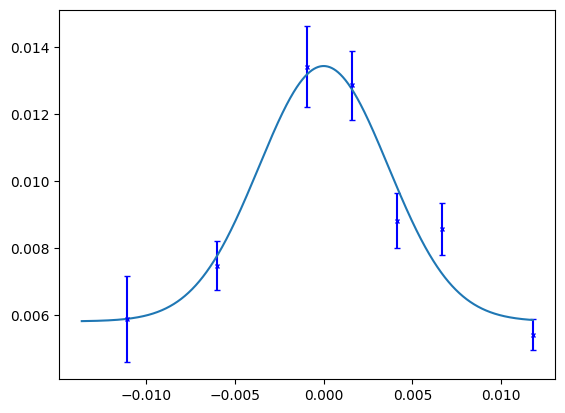

In [78]:
filepath3 = "110125/1RelativeAbsFar110125.csv"

df = pd.read_csv(filepath3)

x_full  = np.concatenate([df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy()])
y_full  = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),df['Scale3'].to_numpy(),df['Scale4'].to_numpy()])

# x_full = df['height']

# # Compute mean and standard error across Scale1–Scale4
# scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

# y_full = np.mean(scales, axis=1)
# y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


def gaussian(x, A, x0, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.015, 500, 100, 0.0], 
    absolute_sigma= False
)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


x_fit = np.linspace(0,1000,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar((x_full - popt[1]) / (39.3701 * 1000), y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "blue")
plt.plot((x_fit - popt[1]) / (39.3701 * 1000), y_fit)

# Extract sigma and its error
sigma = popt[2]
sigma_err = np.sqrt(pvoc[2, 2])

# Calculate widths
FWHM = 2 * np.sqrt(2 * np.log(2)) * sigma
width_1e = 2 * np.sqrt(2) * sigma

# Propagate errors
FWHM_err = 2 * np.sqrt(2 * np.log(2)) * sigma_err
width_1e_err = 2 * np.sqrt(2) * sigma_err

print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")


nozzleheight = 0.150
beamgrowth = width_1e/1000 - nozzleheight
distancenozzle = 12.3

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * width_1e_err   # propagate

print(f"Divergence half-angle = {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")


nozzleheight = 0.150
beamgrowth = FWHM/1000 - nozzleheight
distancenozzle = 12.3

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * FWHM_err   # propagate

print(f"Divergence half-angle FWHM= {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")



offset = popt[3]
dx = popt[1]
print(dx)



Results for Rb Ar beam, 11/28/2025. Ar 0.01 SCCM +/- 0.002 SCCM

FWHM = 177.54 ± 9.43
1/e width = 213.25 ± 11.33
Divergence half-angle = 0.737 ± 0.132 deg
Divergence half-angle FWHM= 0.321 ± 0.110 deg
443.3872346813897


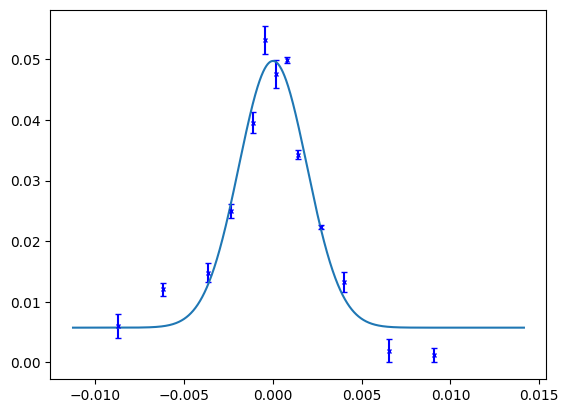

In [4]:
filepathRbAr = "112825/RelativeAbs_near_0.01SCCM_112825.csv"

df = pd.read_csv(filepathRbAr)

x_full  = np.concatenate([df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy(),df['height'].to_numpy()])
y_full  = np.concatenate([df['Scale1'].to_numpy(), df['Scale2'].to_numpy(),df['Scale3'].to_numpy(),df['Scale4'].to_numpy()])


def gaussian(x, A, x0, sigma, offset):
    return A * np.exp(- (x - x0)**2 / (2.0 * sigma**2)) + offset


popt, pvoc = curve_fit(
    gaussian, x_full, y_full,
    p0 = [0.015, 500, 100, 0.0], 
    absolute_sigma= False
)

x_full = df['height']

# Compute mean and standard error across Scale1–Scale4
scales = df[['Scale1', 'Scale2', 'Scale3', 'Scale4']].to_numpy()

y_full = np.mean(scales, axis=1)
y_err  = np.std(scales, axis=1, ddof=1) / np.sqrt(scales.shape[1])


x_fit = np.linspace(0,1000,2000)
y_fit = gaussian(x_fit, *popt)

plt.errorbar((x_full - popt[1]) / (39.3701 * 1000), y_full, yerr=y_err,fmt='x',markersize=3,linestyle='None',capsize=2,c= "blue")
plt.plot((x_fit - popt[1]) / (39.3701 * 1000), y_fit)

# Extract sigma and its error
sigma = popt[2]
sigma_err = np.sqrt(pvoc[2, 2])

# Calculate widths
FWHM = 2 * np.sqrt(2 * np.log(2)) * sigma
width_1e = 2 * np.sqrt(2) * sigma

# Propagate errors
FWHM_err = 2 * np.sqrt(2 * np.log(2)) * sigma_err
width_1e_err = 2 * np.sqrt(2) * sigma_err

print(f"FWHM = {FWHM:.2f} ± {FWHM_err:.2f}")
print(f"1/e width = {width_1e:.2f} ± {width_1e_err:.2f}")


nozzleheight = 0.150
beamgrowth = width_1e/1000 - nozzleheight
distancenozzle = 2.46

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * width_1e_err   # propagate

print(f"Divergence half-angle = {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")


nozzleheight = 0.150
beamgrowth = FWHM/1000 - nozzleheight
distancenozzle = 2.46

divhalfangle = math.atan((beamgrowth/2)/distancenozzle)


# Error propagation assuming only width_1e has uncertainty
du_dw = 1.0 / (2000 * distancenozzle)              # ∂u/∂width_1e
u = (beamgrowth/2) / distancenozzle
dtheta_du = 1.0 / (1.0 + u**2)                     # ∂atan(u)/∂u
dtheta_dw = dtheta_du * du_dw                      # chain rule

divhalfangle_err = abs(dtheta_dw) * FWHM_err   # propagate

print(f"Divergence half-angle FWHM= {(divhalfangle*180/math.pi):.3f} ± {(divhalfangle_err*180/math.pi):.3f} deg")



offset = popt[3]
dx = popt[1]
print(dx)

0.5451251305555878
sigma = 0.669064 ± 0.086
P(|X| ≤ 0.5) = 0.545125 ± 0.058


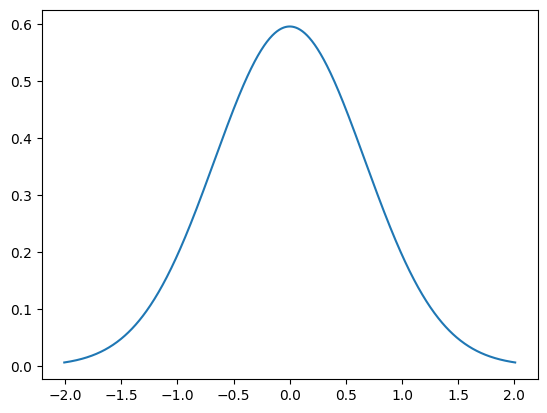

In [3]:
#Capture efficiency  
Distance_z1_gr = (19.685-2.46)*12*100#ft

div_1e = 0.737 #degree
div_1e_err =0.132 #degree

z1_1e =  213.25 #thous an inch
z1_1e_err = 11.3 #thous an inch

gr_1e = (z1_1e + 2*Distance_z1_gr*math.tan(div_1e*math.pi/180))*2.54/1000 #cm


# get normal (gaussian) dist
sigma = gr_1e / (2*np.sqrt(2))
mu = 0
x = np.linspace(-3*sigma, 3*sigma, 1000)
f = norm.pdf(x, mu, sigma)

plt.plot(x,f)

P = norm.cdf(0.5, mu, sigma) - norm.cdf(-0.5, mu, sigma)
print(P)

# inputs (your values)
Distance_z1_gr = (19.685-2.46)*12*100      # same units you used for D
div_deg = 0.737
div_deg_err = 0.132
z_thou = 213.25
z_thou_err = 11.3

# constants
c = 2.54/1000.0                             # cm per thou
theta = math.radians(div_deg)
D = Distance_z1_gr

# g_{1/e}, sigma
g_1e = (z_thou + 2*D*math.tan(theta)) * c   # cm
sigma = g_1e / (2*math.sqrt(2))

# derivatives
dg_dz = c
dg_ddivdeg = 2*D*(1/math.cos(theta))**2 * c * math.pi/180.0
dsigma_dz = dg_dz / (2*math.sqrt(2))
dsigma_ddivdeg = dg_ddivdeg / (2*math.sqrt(2))

# sigma uncertainty
var_sigma = (dsigma_dz * z_thou_err)**2 + (dsigma_ddivdeg * div_deg_err)**2
sigma_err = math.sqrt(var_sigma)

# probability within [-0.5, 0.5]
a = 0.5
P = norm.cdf(a, 0, sigma) - norm.cdf(-a, 0, sigma)

# dP/dsigma
t = a / sigma
phi = math.exp(-0.5*t*t) / math.sqrt(2*math.pi)
dP_dsigma = -2*a*phi / (sigma**2)

# P uncertainty
P_err = abs(dP_dsigma) * sigma_err

print(f"sigma = {sigma:.6g} ± {sigma_err:.2g}")
print(f"P(|X| ≤ 0.5) = {P:.6f} ± {P_err:.2g}")

